In [8]:
%run -i ./01_cleaning.ipynb

{'Students': (1002, 12), 'Groups': (41, 8), 'Sessions': (1442, 6), 'Records': (34834, 16), 'Payments': (8713, 9)}
Students  (1002, 12)
Groups    (41, 8)
Sessions  (1442, 6)
Records   (34834, 16)
Payments  (8713, 9)
القيم الناقصة في كل جدول (الأعمدة اللي فيها فاضي بس):

Students: {'name': 1, 'phone': 1, 'parent_phone': 1, 'group_id': 1, 'gender': 1, 'grade': 1, 'school_type': 1, 'area': 1, 'join_date': 1, 'status': 1, 'leave_date': 972}

Groups: {'group_name': 1, 'day': 1, 'time': 1, 'grade': 1, 'track': 1, 'monthly_fee': 1, 'start_date': 1}

Sessions: {'group_id': 1, 'date': 1, 'session_number': 1, 'month': 1, 'session_type': 1}

Records: {'student_id': 43, 'session_id': 43, 'date': 43, 'attendance': 43, 'homework': 43, 'exam_score': 2744, 'max_exam_score': 2745, 'percentage': 2744, 'notes': 2721, 'student_session_number': 43, 'group_month': 43, 'group_session': 43, 'student_month': 43, 'student_session': 44, 'attendance_notes': 31883}

Payments: {'student_id': 10, 'month_label': 10, '

In [15]:
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.dummy import DummyRegressor
from sklearn.model_selection import GroupKFold, cross_validate, RandomizedSearchCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance

pd.set_option('display.width', 200); pd.set_option('display.max_columns', 50)
TARGET = 'percentage'   # لو عايز exam_score غيّره هنا (بس مش هينفع تستخدم max_exam_score كـ feature)
print('train students:', len(train_ids), '| test students:', len(test_ids))

train students: 800 | test students: 200


In [16]:
HW_MAP  = {'ممتاز': 5, 'جيد جدا': 4, 'جيد': 3, 'مقبول': 2, 'ضعيف': 1, 'لم يسلم': 0}
ATT_MAP = {'present': 1, 'late': 1, 'absent': 0, 'excused': 0}
num = lambda s: pd.to_numeric(s, errors='coerce')

# أعمدة مش هتدخل كـ features (هوية، تسريب، أو معلومة من المستقبل)
DROP_STU = ['phone', 'parent_phone', 'status', 'leave_date', 'name', 'student_name', 'group_id']


def build_table(T):
    rec = T['Records'].dropna(subset=['student_id', 'session_id']).copy()
    for c in ['exam_score', 'max_exam_score', 'percentage']:
        rec[c] = num(rec[c])
    rec = rec.drop(columns=['group_id'], errors='ignore')

    ses = T['Sessions'][['session_id', 'group_id', 'session_number', 'month']].copy()
    ses['session_number'] = num(ses['session_number']); ses['month'] = num(ses['month'])

    df = rec.merge(ses, on='session_id', how='left')
    df = df.sort_values(['student_id', 'session_number']).reset_index(drop=True)

    df['hw_score'] = df['homework'].map(HW_MAP)
    df['attended'] = df['attendance'].map(ATT_MAP)
    df['is_late']  = (df['attendance'] == 'late').astype(int)

    # تاريخ الطالب: كله من الحصص اللي قبل الحالية (shift(1))
    g = df.groupby('student_id')
    df['prior_avg_pct']    = g[TARGET].transform(lambda s: s.shift(1).expanding().mean())
    df['prior_last3_pct']  = g[TARGET].transform(lambda s: s.shift(1).rolling(3, min_periods=1).mean())
    df['prior_last_pct']   = g[TARGET].transform(lambda s: s.shift(1).ffill())
    df['prior_n_exams']    = g[TARGET].transform(lambda s: s.shift(1).notna().cumsum())
    df['prior_attendance'] = g['attended'].transform(lambda s: s.shift(1).expanding().mean())
    df['prior_hw']         = g['hw_score'].transform(lambda s: s.shift(1).expanding().mean())

    stu = T['Students'].drop(columns=[c for c in DROP_STU if c in T['Students'].columns])
    grp = T['Groups']
    df = df.merge(stu, on='student_id', how='left').merge(grp, on='group_id', how='left', suffixes=('', '_grp'))
    return df


tr_all, te_all = build_table(train), build_table(test)
tr = tr_all[tr_all[TARGET].notna()].reset_index(drop=True)
te = te_all[te_all[TARGET].notna()].reset_index(drop=True)
print(f'صفوف التدريب: {len(tr)} (من {len(tr_all)}) | صفوف الاختبار: {len(te)} (من {len(te_all)})')
print('توزيع الـ target في الـ train:'); print(tr[TARGET].describe().round(3).to_string())

صفوف التدريب: 25611 (من 27796) | صفوف الاختبار: 6454 (من 6969)
توزيع الـ target في الـ train:
count    25611.000
mean         0.825
std          0.161
min          0.000
25%          0.750
50%          0.850
75%          0.950
max          1.000


In [17]:
ENGINEERED = ['session_number', 'month', 'is_late', 'hw_score',
              'prior_avg_pct', 'prior_last3_pct', 'prior_last_pct', 'prior_n_exams', 'prior_attendance', 'prior_hw']
HISTORY    = ['prior_avg_pct', 'prior_last3_pct', 'prior_last_pct', 'prior_n_exams', 'prior_attendance', 'prior_hw']
EXCLUDE = {'record_id', 'student_id', 'session_id', 'payment_id', 'exam_score', 'max_exam_score', TARGET,
           'attendance', 'attended', 'homework', 'date'} | set(ENGINEERED)

num_cols, cat_cols, skipped = list(ENGINEERED), [], []
for c in tr.columns:
    if c in EXCLUDE: continue
    as_num = num(tr[c])
    if tr[c].notna().sum() and as_num.notna().sum() / tr[c].notna().sum() > 0.9:
        num_cols.append(c); tr[c] = as_num; te[c] = num(te[c])
    elif c == 'group_id' or tr[c].nunique() <= 30:
        cat_cols.append(c)
        for d in (tr, te): d[c] = d[c].astype('object').where(d[c].notna(), np.nan)
    else:
        skipped.append(c)

FEATURES = num_cols + cat_cols
print('رقمية  :', num_cols); print('تصنيفية:', cat_cols); print('اتشالت (قيمها كتير/نص حر):', skipped)

X_tr, y_tr, g_tr = tr[FEATURES], tr[TARGET], tr['student_id']
X_te, y_te       = te[FEATURES], te[TARGET]

رقمية  : ['session_number', 'month', 'is_late', 'hw_score', 'prior_avg_pct', 'prior_last3_pct', 'prior_last_pct', 'prior_n_exams', 'prior_attendance', 'prior_hw', 'student_session_number', 'group_month', 'group_session', 'student_month', 'student_session', 'join_date', 'monthly_fee', 'start_date']
تصنيفية: ['notes', 'attendance_notes', 'group_id', 'gender', 'grade', 'school_type', 'area', 'day', 'time', 'grade_grp', 'track']
اتشالت (قيمها كتير/نص حر): ['group_name']


In [18]:
SEED = 42

def make_pipeline(model, scale, nums, cats):
    num_steps = [('imp', SimpleImputer(strategy='median', add_indicator=True))]
    if scale: num_steps.append(('sc', StandardScaler()))
    parts = [('num', Pipeline(num_steps), nums)]
    if cats:
        parts.append(('cat', Pipeline([('imp', SimpleImputer(strategy='most_frequent')),
                                       ('ohe', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), cats))
    return Pipeline([('prep', ColumnTransformer(parts)), ('model', model)])


baseline = make_pipeline(DummyRegressor(strategy='mean'), True, num_cols, cat_cols)
linear   = make_pipeline(LinearRegression(), True, num_cols, cat_cols)
hgb      = make_pipeline(HistGradientBoostingRegressor(early_stopping=False, random_state=SEED), False, num_cols, cat_cols)

In [19]:
cv = GroupKFold(n_splits=5)
scoring = {'MAE': 'neg_mean_absolute_error', 'RMSE': 'neg_root_mean_squared_error', 'R2': 'r2'}
rows = {}
for name, m in [('Baseline (mean)', baseline), ('Linear Regression', linear), ('HistGradientBoosting', hgb)]:
    r = cross_validate(m, X_tr, y_tr, groups=g_tr, cv=cv, scoring=scoring)
    rows[name] = {'MAE (pts)': -r['test_MAE'].mean() * 100, 'RMSE (pts)': -r['test_RMSE'].mean() * 100, 'R2': r['test_R2'].mean()}
pd.DataFrame(rows).T.round(3)

,MAE (pts),RMSE (pts),R2
Baseline (mean),12.363,16.113,-0.002
Linear Regression,56.101,798.801,-11394.206
HistGradientBoosting,2.745,3.542,0.951


In [20]:
param_dist = {
    'model__learning_rate':     [0.03, 0.05, 0.1],
    'model__max_iter':          [150, 300, 500],
    'model__max_depth':         [3, 5, None],
    'model__max_leaf_nodes':    [15, 31],
    'model__min_samples_leaf':  [20, 50, 100],
    'model__l2_regularization': [0.0, 1.0, 10.0],
}
search = RandomizedSearchCV(hgb, param_dist, n_iter=20, cv=GroupKFold(n_splits=5),
                            scoring='neg_mean_absolute_error', random_state=SEED, n_jobs=-1)
search.fit(X_tr, y_tr, groups=g_tr)
hgb_best = search.best_estimator_
print('أحسن إعدادات:', {k.replace('model__', ''): v for k, v in search.best_params_.items()})
print(f'CV MAE: {-search.best_score_ * 100:.3f} نقطة مئوية')

أحسن إعدادات: {'min_samples_leaf': 20, 'max_leaf_nodes': 15, 'max_iter': 500, 'max_depth': 5, 'learning_rate': 0.05, 'l2_regularization': 0.0}
CV MAE: 2.743 نقطة مئوية


In [21]:
final = {'Baseline (mean)': baseline, 'Linear Regression': linear, 'HistGradientBoosting (tuned)': hgb_best}
preds, res = {}, {}
for name, m in final.items():
    m.fit(X_tr, y_tr)
    p = np.clip(m.predict(X_te), 0, 1)           # الدرجة لازم تبقى بين 0 و 1
    preds[name] = p
    res[name] = {'MAE (pts)': mean_absolute_error(y_te, p) * 100,
                 'RMSE (pts)': np.sqrt(mean_squared_error(y_te, p)) * 100,
                 'R2': r2_score(y_te, p)}
results = pd.DataFrame(res).T.round(3)
print('الأخطاء بالنقاط المئوية (pts) من 100، يعني MAE = 5 معناها إن الموديل بيغلط 5 نقط من 100 في المتوسط.')
results

الأخطاء بالنقاط المئوية (pts) من 100، يعني MAE = 5 معناها إن الموديل بيغلط 5 نقط من 100 في المتوسط.


,MAE (pts),RMSE (pts),R2
Baseline (mean),12.837,17.011,-0.002
Linear Regression,2.725,3.602,0.955
HistGradientBoosting (tuned),2.713,3.596,0.955


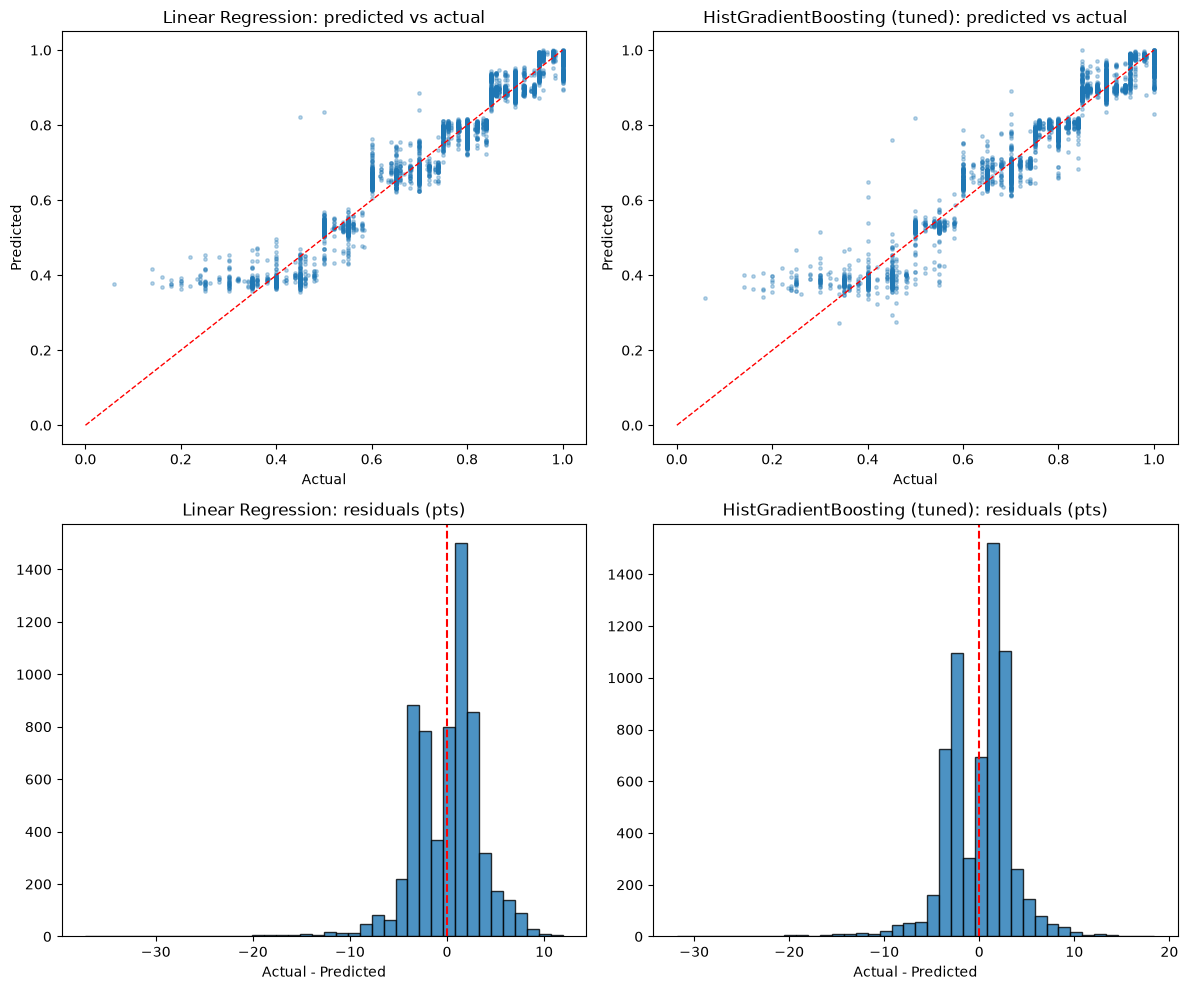

In [22]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
for ax, name in zip(axes[0], ['Linear Regression', 'HistGradientBoosting (tuned)']):
    ax.scatter(y_te, preds[name], s=6, alpha=0.3)
    ax.plot([0, 1], [0, 1], 'r--', lw=1)
    ax.set_title(f'{name}: predicted vs actual'); ax.set_xlabel('Actual'); ax.set_ylabel('Predicted')
for ax, name in zip(axes[1], ['Linear Regression', 'HistGradientBoosting (tuned)']):
    ax.hist((y_te - preds[name]) * 100, bins=40, edgecolor='k', alpha=0.8)
    ax.axvline(0, color='r', ls='--'); ax.set_title(f'{name}: residuals (pts)'); ax.set_xlabel('Actual - Predicted')
plt.tight_layout(); plt.show()

أقوى 15 معامل في Linear Regression:


,coef
cat__notes_ضعيف,-0.2915
cat__notes_ممتاز جدا,0.2520
cat__notes_لازم ولي الأمر يتواصل,-0.2376
cat__notes_ضعف واضح في الأساسيات,-0.2349
cat__notes_ملاحظ إنه مش مذاكر,-0.2316
cat__notes_محتاج خطة علاج,-0.2209
cat__notes_حل كل التمارين صح,0.2064
cat__notes_مشاركة ممتازة في الحصة,0.2048
cat__notes_تحسن ملحوظ,0.2024
cat__notes_طالب متميز,0.2012



أهمية الـ features في HistGradientBoosting (زيادة الـ MAE بالنقاط لما نبوّظ الـ feature):


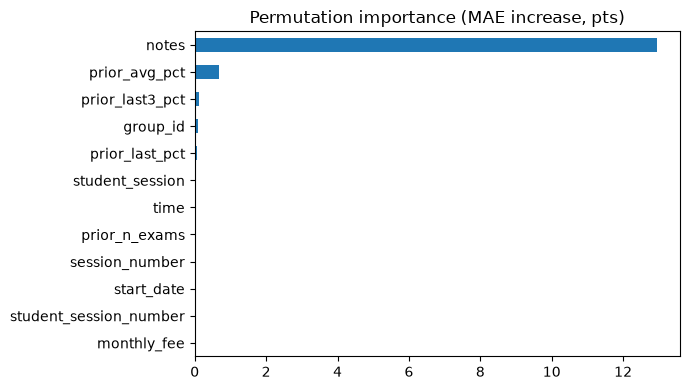

In [23]:
# معاملات الـ Linear (الـ numeric متعمله scaling، فحجم المعامل = قوة التأثير تقريبًا)
prep = linear.named_steps['prep']
names = prep.get_feature_names_out()
coefs = pd.Series(linear.named_steps['model'].coef_, index=names).sort_values(key=abs, ascending=False)
print('أقوى 15 معامل في Linear Regression:')
display(coefs.head(15).round(4).to_frame('coef'))

# أهمية الـ features في الموديل الأقوى (permutation importance على الـ test)
imp = permutation_importance(hgb_best, X_te, y_te, n_repeats=5, random_state=SEED,
                             scoring='neg_mean_absolute_error', n_jobs=-1)
imp_s = pd.Series(imp.importances_mean * 100, index=FEATURES).sort_values(ascending=False)
print('\nأهمية الـ features في HistGradientBoosting (زيادة الـ MAE بالنقاط لما نبوّظ الـ feature):')
imp_s.head(12).sort_values().plot.barh(figsize=(7, 4), title='Permutation importance (MAE increase, pts)')
plt.tight_layout(); plt.show()

In [24]:
nums_nh = [c for c in num_cols if c not in HISTORY]
rows = {}
for name, model, scale in [('Linear (no history)', LinearRegression(), True),
                           ('HistGB (no history)', HistGradientBoostingRegressor(early_stopping=False, random_state=SEED, **{k.replace('model__', ''): v for k, v in search.best_params_.items()}), False)]:
    m = make_pipeline(model, scale, nums_nh, cat_cols).fit(X_tr[nums_nh + cat_cols], y_tr)
    p = np.clip(m.predict(X_te[nums_nh + cat_cols]), 0, 1)
    rows[name] = {'MAE (pts)': mean_absolute_error(y_te, p) * 100, 'RMSE (pts)': np.sqrt(mean_squared_error(y_te, p)) * 100, 'R2': r2_score(y_te, p)}
pd.concat([results, pd.DataFrame(rows).T.round(3)])

,MAE (pts),RMSE (pts),R2
Baseline (mean),12.837,17.011,-0.002
Linear Regression,2.725,3.602,0.955
HistGradientBoosting (tuned),2.713,3.596,0.955
Linear (no history),2.850,3.730,0.952
HistGB (no history),2.826,3.711,0.952
